In [1]:
import torch
import torch.nn as nn
import numpy as np
import pandas as pd

from torchvision.models import resnet18
from sklearn.metrics import roc_auc_score

from src.dataset import ChestXrayDataset

from torch.utils.data import DataLoader
from torchvision import transforms

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)

Device: cuda


In [2]:
model = resnet18(weights=None)
model.fc = nn.Linear(model.fc.in_features, 14)

In [3]:
transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]),
])

In [4]:
train_df = pd.read_csv("metadata/train.csv")
val_df = pd.read_csv("metadata/val.csv")
train_dataset = ChestXrayDataset(train_df, data_dir='data/data/', transform=transform)
val_dataset = ChestXrayDataset(val_df, data_dir='data/data/', transform=transform)
train_loader = DataLoader(
    train_dataset,
    batch_size=32,
    shuffle=True,
    num_workers=6,
    pin_memory=True,
    persistent_workers=True
)

val_loader = DataLoader(
    val_dataset,
    batch_size=32,
    shuffle=False,
    num_workers=6,
    pin_memory=True,
    persistent_workers=True
)

## AUC ROC after 1 epoch

In [5]:
from pathlib import Path

checkpoint_path = Path("checkpoints/resnet18_epoch1.pth")

checkpoint = torch.load(
    checkpoint_path,
    map_location="cpu",
    weights_only=True,
)

model.load_state_dict(checkpoint["model_state_dict"])
model = model.to(device)
model.eval()

print("Loaded epoch:", checkpoint["epoch"])
print("Model device:", next(model.parameters()).device)

model.eval()

all_labels = []
all_probs = []

with torch.inference_mode():
    for batch_idx, (images, labels) in enumerate(val_loader):
        images = images.to(device)

        logits = model(images)
        probs = torch.sigmoid(logits)

        all_labels.append(labels.cpu().numpy())
        all_probs.append(probs.cpu().numpy())

        if (batch_idx + 1) % 100 == 0:
            print(f"Processed {batch_idx + 1}/{len(val_loader)} batches")

y_true = np.concatenate(all_labels, axis=0)
y_prob = np.concatenate(all_probs, axis=0)

print("Labels:", y_true.shape)
print("Predictions:", y_prob.shape)

pathology_names = [
    "Atelectasis", "Cardiomegaly", "Effusion", "Infiltration",
    "Mass", "Nodule", "Pneumonia", "Pneumothorax",
    "Consolidation", "Edema", "Emphysema", "Fibrosis",
    "Pleural Thickening", "Hernia"
]
df = pd.DataFrame({'Name': pathology_names, 'ROC AUC': roc_auc_score(y_true, y_prob, average=None)})
df

Processed 100/1366 batches
Processed 200/1366 batches
Processed 300/1366 batches
Processed 400/1366 batches
Processed 500/1366 batches
Processed 600/1366 batches
Processed 700/1366 batches
Processed 800/1366 batches
Processed 900/1366 batches
Processed 1000/1366 batches
Processed 1100/1366 batches
Processed 1200/1366 batches
Processed 1300/1366 batches
Labels: (10923, 14)
Predictions: (10923, 14)


In [9]:
roc_auc_score(y_true, y_prob)

0.8017257854205859

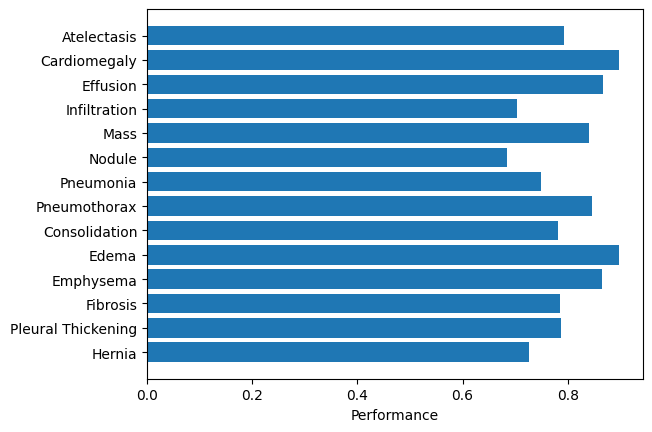

In [12]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots()

ax.barh(df['Name'], df['ROC AUC'])
ax.yaxis.set_inverted(True)  # arrange data from top to bottom
ax.set_xlabel('Performance')

plt.show()

In [13]:
results_dir = Path("results")
results_dir.mkdir(exist_ok=True)
df.to_csv(results_dir/"validation_auroc.csv", index=False)

## Making it modular

In [10]:
from src.evaluate import load_checkpoint, evaluate_model

In [13]:
pathology_names = [
    "Atelectasis", "Cardiomegaly", "Effusion", "Infiltration",
    "Mass", "Nodule", "Pneumonia", "Pneumothorax",
    "Consolidation", "Edema", "Emphysema", "Fibrosis",
    "Pleural Thickening", "Hernia"
]

model = load_checkpoint(
    model,
    "checkpoints/resnet18_adam_epoch_3.pth",
    device
)

df, macro_auc = evaluate_model(
    model,
    val_loader,
    device,
    pathology_names
)

display(df)

Loaded epoch: 3
Processed 100/342 batches
Processed 200/342 batches
Processed 300/342 batches
Macro ROC-AUC: 0.8199


,Name,ROC AUC
0,Atelectasis,0.819627
1,Cardiomegaly,0.914616
2,Effusion,0.871743
3,Infiltration,0.716445
4,Mass,0.852727
5,Nodule,0.702777
6,Pneumonia,0.746072
7,Pneumothorax,0.860454
8,Consolidation,0.793783
9,Edema,0.915594


## Trained for 3 epochs

In [5]:
from src.train import train

In [12]:
optimizer = torch.optim.Adam(model.parameters(), lr=1e-4)
criterion = torch.nn.BCEWithLogitsLoss()

model = train(
    model=model,
    optimizer=optimizer,
    criterion=criterion,
    train_loader=train_loader,
    val_loader=val_loader,
    device=device,
    epochs=3,
    print_every=100,
    checkpoint_dir="checkpoints",
    run_name="resnet18_adam",
    start_epoch=2,
)

Epoch 3 | Batch 100/2821 | Train loss: 0.1365 | Interval: 1.6 min | Elapsed: 1.6 min | ETA: 44.7 min
Epoch 3 | Batch 200/2821 | Train loss: 0.1344 | Interval: 1.7 min | Elapsed: 3.3 min | ETA: 43.3 min
Epoch 3 | Batch 300/2821 | Train loss: 0.1331 | Interval: 1.7 min | Elapsed: 5.0 min | ETA: 42.0 min
Epoch 3 | Batch 400/2821 | Train loss: 0.1335 | Interval: 1.6 min | Elapsed: 6.6 min | ETA: 40.2 min
Epoch 3 | Batch 500/2821 | Train loss: 0.1338 | Interval: 1.6 min | Elapsed: 8.3 min | ETA: 38.3 min
Epoch 3 | Batch 600/2821 | Train loss: 0.1336 | Interval: 1.8 min | Elapsed: 10.0 min | ETA: 37.1 min
Epoch 3 | Batch 700/2821 | Train loss: 0.1335 | Interval: 1.6 min | Elapsed: 11.7 min | ETA: 35.3 min
Epoch 3 | Batch 800/2821 | Train loss: 0.1340 | Interval: 1.8 min | Elapsed: 13.4 min | ETA: 33.9 min
Epoch 3 | Batch 900/2821 | Train loss: 0.1336 | Interval: 1.7 min | Elapsed: 15.1 min | ETA: 32.3 min
Epoch 3 | Batch 1000/2821 | Train loss: 0.1341 | Interval: 1.6 min | Elapsed: 16.8 min 

KeyboardInterrupt: 